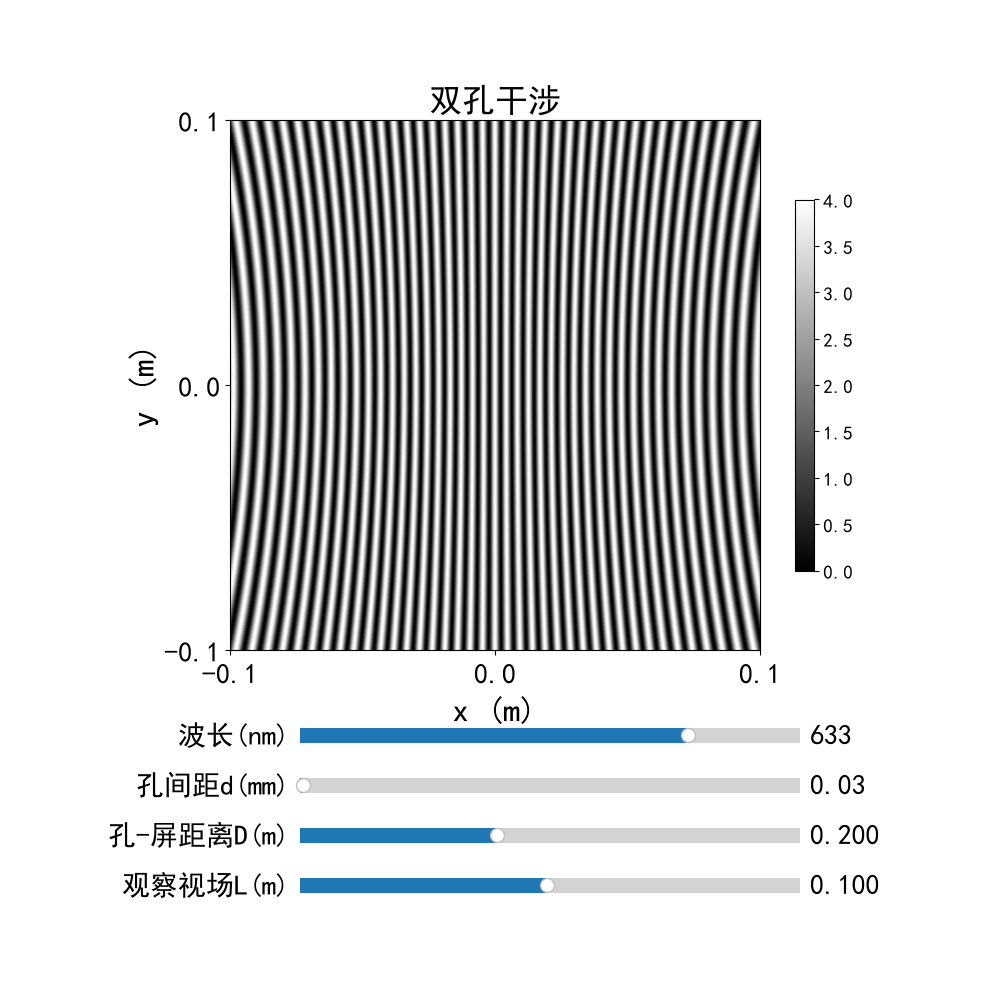

In [1]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider
# ==========解决中文显示、负号乱码==========
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

# -------------------------- 基础画布 --------------------------
fig, ax = plt.subplots(figsize=(10, 10))
plt.subplots_adjust(left=0.2, bottom=0.35)  # 预留底部空间放滑块

# ========= 默认物理参数 =========
lam0 = 633e-9    # 波长 633nm He-Ne激光
d0 = 0.00003       # 两孔间距初始值
D0 = 0.2         # 孔屏到观察屏距离
L0 = 0.1         # 视场范围
nx, ny = 800, 800 # 分辨率，兼顾计算速度

# 强度计算函数（严格球面波）
def calc_intensity(lam, d, D, L):
    holes = np.array([[d/2,0],[-d/2,0]])
    Xg, Yg = np.meshgrid(np.linspace(-L, L, nx), np.linspace(-L, L, ny))
    U = 0
    k = 2 * np.pi / lam
    for (xh, yh) in holes:
        r = np.sqrt((Xg - xh)**2 + (Yg - yh)**2 + D**2)
        phase = k * r
        U += np.exp(1j * phase)
    I = np.abs(U)**2
    return I, Xg, Yg

# 初始绘图
I_init, Xg_init, Yg_init = calc_intensity(lam0, d0, D0, L0)
im = ax.imshow(I_init, cmap='gray', extent=[-L0, L0, -L0, L0])

# -------- 设置标题、坐标轴文字大小 --------
ax.set_xlabel("x (m)", fontsize=24)
ax.set_ylabel("y (m)", fontsize=24)
ax.set_title("双孔干涉", fontsize=24)
ax.tick_params(labelsize=20)
# 初始刻度：-L0, 0, +L0
ax.set_xticks([-L0, 0, L0])
ax.set_yticks([-L0, 0, L0])
cbar = plt.colorbar(im, ax=ax, shrink=0.7)
cbar.ax.tick_params(labelsize=14)

# -------------------------- 滑块定义 --------------------------
ax_lam  = plt.axes([0.3, 0.25, 0.5, 0.03])
ax_d    = plt.axes([0.3, 0.20, 0.5, 0.03])
ax_D    = plt.axes([0.3, 0.15, 0.5, 0.03])
ax_L    = plt.axes([0.3, 0.10, 0.5, 0.03])

# 物理参数滑块
s_lam = Slider(ax_lam, '波长(nm)', 400, 700, valinit=lam0*1e9)
s_d = Slider(ax_d, '孔间距d(mm)', 0.01, 3.0, valinit=d0*1e3)
s_D = Slider(ax_D, '孔-屏距离D(m)', 0.005, 0.5, valinit=D0)
s_L = Slider(ax_L, '观察视场L(m)', 0.002, 0.2, valinit=L0)

# 滑块标签字号
s_lam.label.set_fontsize(20)
s_d.label.set_fontsize(20)
s_D.label.set_fontsize(20)
s_L.label.set_fontsize(20)
s_lam.valtext.set_fontsize(20)
s_d.valtext.set_fontsize(20)
s_D.valtext.set_fontsize(20)
s_L.valtext.set_fontsize(20)

# -------------------------- 更新回调函数 --------------------------
def update(val):
    lam = s_lam.val * 1e-9
    d   = s_d.val * 1e-3
    D   = s_D.val
    L   = s_L.val
    I, Xg, Yg = calc_intensity(lam, d, D, L)
    im.set_data(I)
    im.set_extent([-L, L, -L, L])
    ax.set_xlim(-L, L)
    ax.set_ylim(-L, L)
    # 核心：三个刻度：-L, 0, +L
    ax.set_xticks([-L, 0, L])
    ax.set_yticks([-L, 0, L])
    ax.set_title(f"λ={lam*1e9:.0f}nm, d={d*1e3:.2f}mm, D={D:.2f}m", fontsize=14)
    ax.tick_params(labelsize=10)
    fig.canvas.draw_idle()

s_lam.on_changed(update)
s_d.on_changed(update)
s_D.on_changed(update)
s_L.on_changed(update)

plt.show()
